# 전체 목차

## 1. 환경 세팅 및 데이터 로드
1-1. 필수 라이브러리 임포트
1-2. 원천 데이터(df_analysis.csv) 로드
1-3. 로드 후 shape 확인

## 2. 결측치 처리
2-1. FN, Active -> 0 대치 (마케팅 미동의 의미)
2-2. age → 중앙값 대치
2-3. club_member_status, fashion_news_frequency, index_group_name, product_group_name → 'UNKNOWN' 대치
2-4. avg_purchase_interval, std_purchase_interval → NaN 유지 (트리 모델 위임, 선형 모델 사용 시 median 대치 주석 처리)


## 3. 메모리 다운 캐스팅
3-1. 범주형 컬럼 → category 타입 변환
3-2. 정수형 컬럼 → int32 / int8 다운캐스팅
3-3. 실수형 컬럼 → float32 / float16 다운캐스팅

## 4. 피처 인코딩 (Feature Encoding)
4-1. 범주형 변수 원-핫 인코딩 (pd.get_dummies, drop_first=False)
4-2. 불필요한 식별자(customer_id) 제거

## 5. 전처리 완료 데이터 저장 및 검증

5-1. hnm_churn_processed.csv 저장
5-2. 저장 후 shape, 결측치 0건, 컬럼 목록 확인

## 6. 데이터셋 분할

6-1. 독립변수 X, 종속변수 y 정의
6-2. Train / Validation 8:2 Stratified Split (random_state=42)
6-3. 분할 후 클래스 비율 확인 및 시각화

## 1. 환경 세팅 및 데이터 로드
1-1. 필수 라이브러리 임포트
1-2. 원천 데이터(df_analysis.csv) 로드

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 시각화 한글 깨짐 방지 및 스타일 설정
plt.rc('font', family='Malgun Gothic') # Mac 사용자라면 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid")

# 1-2. 원천 데이터 로드
# 앞서 EDA에서 검증했던 그 깨끗한 원본 데이터를 새로 불러옵니다.
df_analysis = pd.read_csv('./data/hnm_churn_dataset.csv')

print("--- 데이터 로드 완료 ---")
print(f"데이터셋 모양(Shape): {df_analysis.shape}")

--- 데이터 로드 완료 ---
데이터셋 모양(Shape): (1143652, 20)



## 2. 데이터 정제 및 전처리 (Data Cleaning)
2-1. 도메인 맞춤형 결측치(NaN) 대치 (FN, Active, age, 범주형 변수)
2-2. 대용량 데이터 대응을 위한 메모리 다운캐스팅 (안정적 압축)


In [3]:
# ==========================================
# 2-1. 도메인 맞춤형 결측치(NaN) 대치
# ==========================================

# 1. 마케팅 관련 결측치는 거부 의사(0)로 간주하여 대치
df_analysis['FN'] = df_analysis['FN'].fillna(0)
df_analysis['Active'] = df_analysis['Active'].fillna(0)

# 2. 나이는 가장 안정적인 통계량인 중앙값으로 채우기
df_analysis['age'] = df_analysis['age'].fillna(df_analysis['age'].median())

# 3. 범주형 변수의 결측치는 새로운 카테고리 'UNKNOWN'으로 통일
cat_fix_cols = ['club_member_status', 'fashion_news_frequency', 'index_group_name', 'product_group_name']
for col in cat_fix_cols:
    df_analysis[col] = df_analysis[col].fillna('UNKNOWN')

print("--- 1차 결측치 처리 완료 ---")


# ==========================================
# 2-2. 대용량 데이터 대응을 위한 메모리 다운캐스팅
# ==========================================

# 1. 문자열 -> 카테고리 변환 (메모리 절감 및 향후 인코딩 준비)
for col in cat_fix_cols:
    df_analysis[col] = df_analysis[col].astype('category')

# 2. 정수형 타입 다운캐스팅
df_analysis['churn'] = df_analysis['churn'].astype('int8')
df_analysis['recency'] = df_analysis['recency'].astype('int32')
df_analysis['frequency'] = df_analysis['frequency'].astype('int32')
df_analysis['frequency_last_90d'] = df_analysis['frequency_last_90d'].astype('int32')
df_analysis['frequency_last_180d'] = df_analysis['frequency_last_180d'].astype('int32')
df_analysis['unique_articles'] = df_analysis['unique_articles'].astype('int32')
df_analysis['unique_product_groups'] = df_analysis['unique_product_groups'].astype('int32')

# 3. 실수형 타입 다운캐스팅
df_analysis['age'] = df_analysis['age'].astype('float32')
df_analysis['price_mean'] = df_analysis['price_mean'].astype('float32')
df_analysis['price_sum'] = df_analysis['price_sum'].astype('float32')
df_analysis['price_max'] = df_analysis['price_max'].astype('float32')
df_analysis['avg_purchase_interval'] = df_analysis['avg_purchase_interval'].astype('float32')
df_analysis['std_purchase_interval'] = df_analysis['std_purchase_interval'].astype('float32')
df_analysis['FN'] = df_analysis['FN'].astype('float16')
df_analysis['Active'] = df_analysis['Active'].astype('float16')

print("--- 메모리 다운캐스팅 완료 ---")
print(df_analysis.info())

--- 1차 결측치 처리 완료 ---
--- 메모리 다운캐스팅 완료 ---
<class 'pandas.DataFrame'>
RangeIndex: 1143652 entries, 0 to 1143651
Data columns (total 20 columns):
 #   Column                  Non-Null Count    Dtype   
---  ------                  --------------    -----   
 0   customer_id             1143652 non-null  str     
 1   churn                   1143652 non-null  int8    
 2   frequency               1143652 non-null  int32   
 3   price_mean              1143652 non-null  float32 
 4   price_sum               1143652 non-null  float32 
 5   price_max               1143652 non-null  float32 
 6   recency                 1143652 non-null  int32   
 7   frequency_last_90d      1143652 non-null  int32   
 8   frequency_last_180d     1143652 non-null  int32   
 9   avg_purchase_interval   1031690 non-null  float32 
 10  std_purchase_interval   924772 non-null   float32 
 11  unique_articles         1143652 non-null  int32   
 12  unique_product_groups   1143652 non-null  int32   
 13  index_group

In [ ]:
# avg_purchase_interval, std_purchase_interval의 NaN은 의도적으로 유지
# - 트리 기반 모델(LightGBM, XGBoost)은 NaN 자체 처리 가능
# - 선형/거리 기반 모델 사용 시 median 대치 필요
#   df_analysis['avg_purchase_interval'] = df_analysis['avg_purchase_interval'].fillna(df_analysis['avg_purchase_interval'].median())
#   df_analysis['std_purchase_interval'] = df_analysis['std_purchase_interval'].fillna(df_analysis['std_purchase_interval'].median())

## 3. 피처 인코딩 (Feature Encoding)
3-1. 범주형 변수 원-핫 인코딩 (pd.get_dummies를 통한 수치화)
3-2. 불필요한 식별자(ID) 제거 및 데이터 구조 최종 정돈
3-3. 인코딩 후 전체 피처 간 상관관계 분석 (Correlation Matrix)


In [4]:
# ==========================================
# 3-1. 범주형 변수 원-핫 인코딩
# ==========================================

cat_cols = ['club_member_status', 'fashion_news_frequency', 'index_group_name', 'product_group_name']

# pd.get_dummies를 활용해 0과 1의 형태로 인코딩을 진행합니다.
# 자료형 크기를 낮추기 위해 dtype='int8' 옵션을 추가합니다.
df_encoded = pd.get_dummies(df_analysis, columns=cat_cols, drop_first=False, dtype='int8')


# ==========================================
# 3-2. 불필요한 식별자(ID) 제거 및 구조 정돈
# ==========================================

# 모델 학습에 불필요한 고유 식별자 문자열 컬럼을 제거합니다.
if 'customer_id' in df_encoded.columns:
    df_encoded = df_encoded.drop(columns=['customer_id'])

print("--- 원-핫 인코딩 및 식별자 제거 완료 ---")
print(f"인코딩 후 데이터 모양(Shape): {df_encoded.shape}")


# ==========================================
# 3-3. 인코딩 후 전체 피처 간 상관관계 분석
# ==========================================

# 모든 변수가 수치화되었으므로 전체 상관계수 행렬을 계산합니다.
# float16 변수들의 오버플로우 방지를 위해 연산 시에만 float32로 변환합니다.
correlation_matrix = df_encoded.astype('float32').corr()

# 타겟 라벨인 'churn'과의 상관계수만 쏙 뽑아내어 절대값 기준으로 내림차순 정렬합니다.
churn_corr = correlation_matrix['churn'].drop('churn') # 자기 자신 제외
churn_corr_sorted = churn_corr.abs().sort_values(ascending=False)

print("\n--- 이탈(churn)과 상관관계가 가장 높은 상위 5개 핵심 피처 ---")
for col in churn_corr_sorted.head(5).index:
    actual_val = correlation_matrix.loc[col, 'churn']
    print(f"{col: <35} : {actual_val:.4f}")

--- 원-핫 인코딩 및 식별자 제거 완료 ---
인코딩 후 데이터 모양(Shape): (1143652, 45)

--- 이탈(churn)과 상관관계가 가장 높은 상위 5개 핵심 피처 ---
recency                             : 0.4812
unique_product_groups               : -0.4695
unique_articles                     : -0.3768
frequency                           : -0.3587
frequency_last_180d                 : -0.3542


## 4. 데이터셋 분할 (Data Split)
4-1. 독립변수(X)와 종속변수(y) 정의
4-2. 클래스 비율을 보존하는 Train / Validation 세트 분리 (8:2)


In [5]:
# ==========================================
# 전처리 완료 데이터 저장
# ==========================================

df_encoded.to_csv('./data/hnm_churn_processed.csv', index=False)

# 저장 후 무결성 검증
df_check = pd.read_csv('./data/hnm_churn_processed.csv')
print(f"저장 완료: {df_check.shape}")
print(f"결측치 합계: {df_check.isnull().sum().sum()}")  # avg/std_purchase_interval NaN은 의도적 유지 → 0이 아니어도 정상
print(f"컬럼 목록:\n{list(df_check.columns)}")

저장 완료: (1143652, 45)
결측치 합계: 330842
컬럼 목록:
['churn', 'frequency', 'price_mean', 'price_sum', 'price_max', 'recency', 'frequency_last_90d', 'frequency_last_180d', 'avg_purchase_interval', 'std_purchase_interval', 'unique_articles', 'unique_product_groups', 'FN', 'Active', 'age', 'club_member_status_ACTIVE', 'club_member_status_LEFT CLUB', 'club_member_status_PRE-CREATE', 'club_member_status_UNKNOWN', 'fashion_news_frequency_Monthly', 'fashion_news_frequency_NONE', 'fashion_news_frequency_Regularly', 'fashion_news_frequency_UNKNOWN', 'index_group_name_Baby/Children', 'index_group_name_Divided', 'index_group_name_Ladieswear', 'index_group_name_Menswear', 'index_group_name_Sport', 'product_group_name_Accessories', 'product_group_name_Bags', 'product_group_name_Cosmetic', 'product_group_name_Furniture', 'product_group_name_Garment Full body', 'product_group_name_Garment Lower body', 'product_group_name_Garment Upper body', 'product_group_name_Garment and Shoe care', 'product_group_name_Inte

In [6]:
# ==========================================
# 4-1. 독립변수(X)와 종속변수(y) 정의
# ==========================================

# 예측해야 하는 타겟 라벨인 churn을 y로, 나머지를 독립변수 X로 정의합니다.
X = df_encoded.drop(columns=['churn'])
y = df_encoded['churn']


# ==========================================
# 4-2. 클래스 비율을 보존하는 Train / Validation 세트 분리 (8:2)
# ==========================================

from sklearn.model_selection import train_test_split

# stratify=y 옵션을 통해 원본 데이터의 이탈 비율(50:50)을 분할 후에도 똑같이 유지합니다.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("--- 데이터셋 분할 완료 ---")
print(f"Train 세트 크기      : X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Validation 세트 크기 : X_val {X_val.shape}, y_val {y_val.shape}")
print(f"Train 세트 이탈율    : \n{y_train.value_counts(normalize=True)}")

--- 데이터셋 분할 완료 ---
Train 세트 크기      : X_train (914921, 44), y_train (914921,)
Validation 세트 크기 : X_val (228731, 44), y_val (228731,)
Train 세트 이탈율    : 
churn
1    0.500198
0    0.499802
Name: proportion, dtype: float64


In [7]:
# 분할 결과도 저장
X_train.to_csv('./data/X_train.csv', index=False)
X_val.to_csv('./data/X_val.csv', index=False)
y_train.to_csv('./data/y_train.csv', index=False)
y_val.to_csv('./data/y_val.csv', index=False)

In [9]:
plt.rc('font', family='Malgun Gothic')   # Windows
# plt.rc('font', family='AppleGothic')  # Mac
plt.rcParams['axes.unicode_minus'] = False

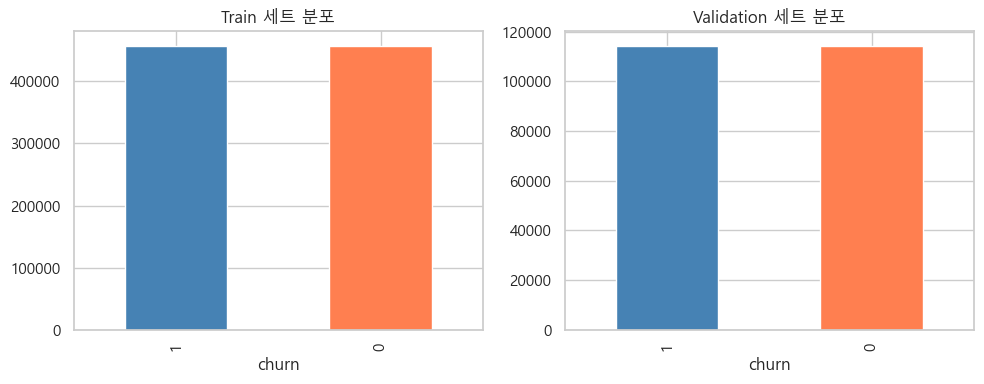

In [10]:
# 시각화 한줄

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().plot(kind='bar', ax=axes[0], title='Train 세트 분포', color=['steelblue', 'coral'])
y_val.value_counts().plot(kind='bar', ax=axes[1], title='Validation 세트 분포', color=['steelblue', 'coral'])
plt.tight_layout()
plt.show()

### 데이터셋 분할 결과 해석

- **Train 세트**: 이탈(1) 약 457,000건, 유지(0) 약 457,000건으로 완전한 50:50 비율 유지
- **Validation 세트**: 이탈(1) 약 114,000건, 유지(0) 약 114,000건으로 동일한 비율 유지
- `stratify=y` 옵션이 정상 작동하여 원본 데이터의 클래스 비율이 분할 후에도 그대로 보존됨
- 클래스 불균형이 없는 상태에서 분할이 이루어졌으므로 **별도의 불균형 보정(SMOTE 등) 없이 모델 학습 진행 가능**